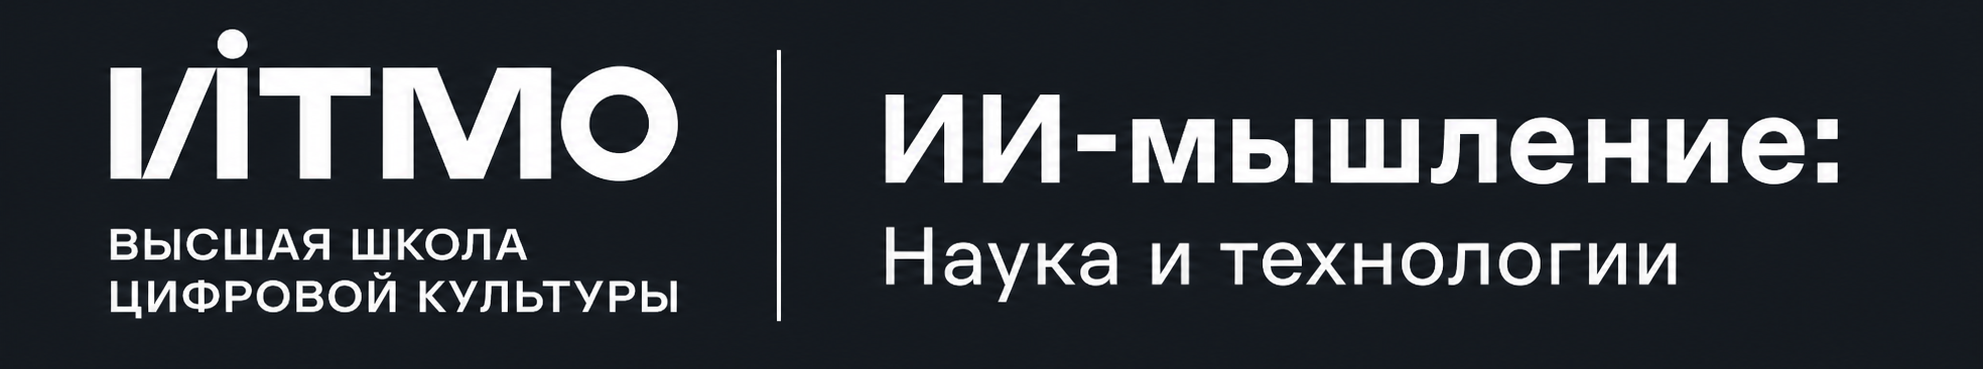

# Неделя 06. Мультимодальные модели (Лайт трек)

## Информация
---
> **ФИО: Абдуллин Ралиф Артурович**
>
> **ИСУ: 564197**
---

## Цель работы

Пройдите путь картинки через мультимодальные модели. Разрежьте её на патчи, как ViT, классифицируйте без обучения через CLIP, найдите похожие картинки по тексту и задайте вопросы VLM, чтобы увидеть, где модель начинает выдумывать.

## Как выполнять работу

- Ответы на «Вопросы на подумать» и декларацию использования ИИ пишите сами.
- В остальном можно пользоваться любыми инструментами, в том числе ИИ. Отметьте это в декларации.
- Не меняйте тестовые ячейки и функции `print_ok` и `print_error`.
- Перед сдачей выполните блокнот целиком через «Среда выполнения» – «Перезапустить сеанс и выполнить все ячейки».

In [2]:
# ruff: noqa: E402, I001, F811, E722
import random
import subprocess
import sys

def print_ok(msg="Все проверки пройдены"):
    print(f"\033[92m[OK]\033[0m {msg}")

def print_error(msg=""):
    print(f"\033[91m[ERROR]\033[0m {msg}")

required_packages = {'numpy': 'numpy', 'torch': 'torch', 'datasets': 'datasets', 'transformers': 'transformers', 'matplotlib': 'matplotlib', 'PIL': 'Pillow'}
for package, pip_name in required_packages.items():
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import numpy as np
import torch

print("Проверка версий библиотек:")
print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"PyTorch: {torch.__version__}")

try:
    import transformers
    print(f"Transformers: {transformers.__version__}")
except ImportError:
    pass

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("\nНайдено устройство Apple Silicon (MPS). Вычисления будут выполняться на GPU Mac.")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"\nНайдено устройство CUDA: {torch.cuda.get_device_name(0)}. Вычисления будут выполняться на GPU.")
else:
    device = torch.device("cpu")
    print("\nВычислительные GPU не найдены. Вычисления будут выполняться на CPU.")

DEVICE = device
print(f"Активное устройство для PyTorch: {device}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Проверка версий библиотек:
Python: 3.13.16
NumPy: 2.4.6
PyTorch: 2.11.0+cu130
Transformers: 5.22.0

Найдено устройство CUDA: Tesla T4. Вычисления будут выполняться на GPU.
Активное устройство для PyTorch: cuda


## Импорты

In [3]:
import re

import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoModelForImageTextToText, AutoProcessor, CLIPModel, CLIPProcessor

print("Загрузка датасета...")
dataset = load_dataset("diffusers/pokemon-gpt4-captions", split="train[:500]")
holdout = load_dataset("diffusers/pokemon-gpt4-captions", split="train[500:520]")

print("Загрузка CLIP...")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

print("Загрузка VLM...")
vlm_processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-256M-Instruct")
vlm_model = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-256M-Instruct").to(DEVICE).eval()

Загрузка датасета...


README.md:   0%|          | 0.00/2.21k [00:00<?, ?B/s]

data/train-00000-of-00001-a1df3b486d3a28(…): reconstructing file:   0%|          |  0.00B / 51.1MB            

data/train-00000-of-00001-a1df3b486d3a28(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/833 [00:00<?, ? examples/s]

Загрузка CLIP...


... (23 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

## Данные

Датасет `diffusers/pokemon-gpt4-captions` – это картинки покемонов и их текстовые описания: поле `image` хранит картинку (PIL), поле `text` – подпись. Берём первые 500 пар, ещё 20 (`holdout`) откладываем для последнего задания.

Типа покемона в датасете нет. Готовая функция `type_label` достаёт его из подписи: ищет в ней имя покемона первого поколения и возвращает его основной тип. Например, для подписи `"Pikachu ..."` это `"electric"`. Метку получает только часть картинок. Их индексы лежат в `labeled_idx`, а сколько таких картинок, печатает первая ячейка ниже. Такие метки шумные, но их хватает, чтобы измерить точность. Вторая ячейка показывает три картинки с подписями и метками.

In [4]:
# Основной тип покемонов первого поколения
_TYPES_BY_NAME = """bulbasaur ivysaur venusaur oddish gloom vileplume bellsprout weepinbell victreebel exeggcute exeggutor tangela:grass
charmander charmeleon charizard vulpix ninetales growlithe arcanine ponyta rapidash magmar flareon moltres:fire
squirtle wartortle blastoise psyduck golduck poliwag poliwhirl poliwrath tentacool tentacruel slowpoke slowbro seel dewgong shellder cloyster krabby kingler horsea seadra goldeen seaking staryu starmie magikarp gyarados lapras vaporeon:water
caterpie metapod butterfree weedle kakuna beedrill paras parasect venonat venomoth scyther pinsir:bug
pidgey pidgeotto pidgeot rattata raticate spearow fearow jigglypuff wigglytuff meowth persian farfetch doduo dodrio lickitung chansey kangaskhan tauros ditto eevee porygon snorlax:normal
ekans arbok nidoran nidorina nidoqueen nidorino nidoking zubat golbat grimer koffing weezing:poison
pikachu raichu magnemite magneton voltorb electrode electabuzz jolteon zapdos:electric
sandshrew sandslash diglett dugtrio cubone marowak rhyhorn rhydon:ground
abra kadabra alakazam drowzee hypno mewtwo:psychic
geodude graveler golem onix omanyte omastar kabuto kabutops aerodactyl:rock
mankey primeape machop machoke machamp hitmonlee hitmonchan:fighting"""
NAME_TO_TYPE = {name: t for line in _TYPES_BY_NAME.splitlines()
                for names, t in [line.split(":")] for name in names.split()}

pokemon_types = ["bug", "electric", "fighting", "fire", "grass", "ground",
                 "normal", "poison", "psychic", "rock", "water"]


def type_label(caption):
    """
    Основной тип первого покемона первого поколения, названного в подписи.

    caption : str
        Подпись к картинке.

    Returns
    -------
    str или None
        Тип из pokemon_types или None, если имени в подписи нет.
    """
    for word in re.findall(r"[a-z]+", caption.lower()):
        if word in NAME_TO_TYPE:
            return NAME_TO_TYPE[word]
    return None


labels = [type_label(caption) for caption in dataset["text"]]
labeled_idx = [i for i, label in enumerate(labels) if label is not None]
print(f"Картинок с меткой типа: {len(labeled_idx)} из {len(dataset)}")

Картинок с меткой типа: 85 из 500


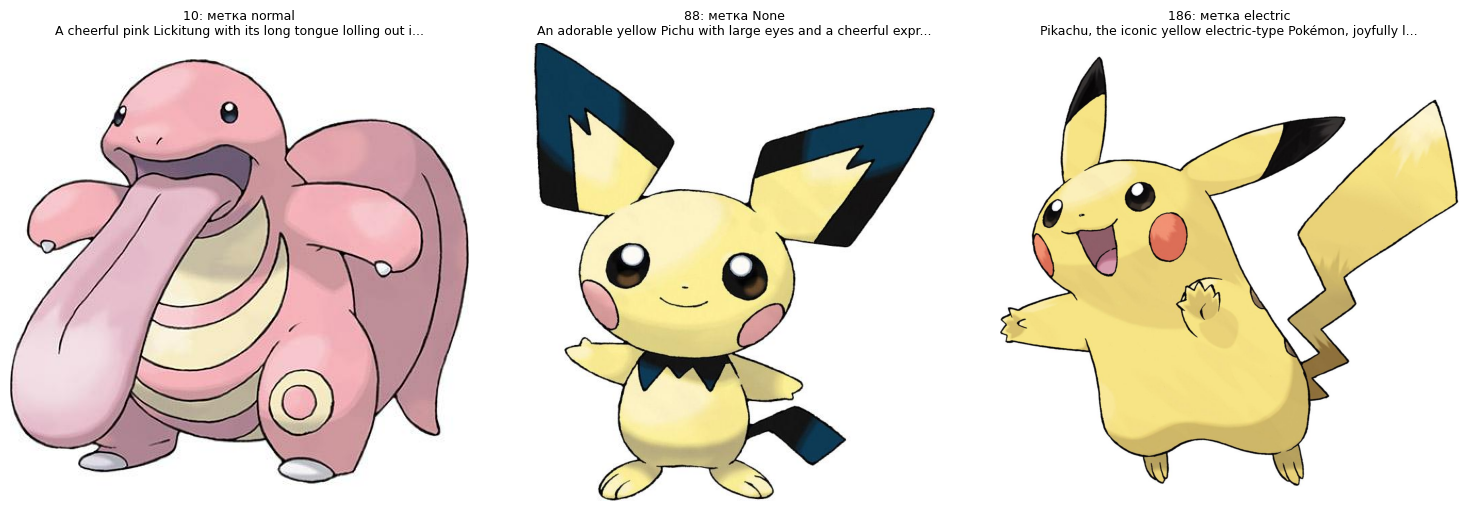

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, i in zip(axes, [10, 88, 186]):
    ax.imshow(dataset[i]["image"])
    ax.set_title(f"{i}: метка {labels[i]}\n{dataset[i]['text'][:60]}...", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Задание 1. Изображение как последовательность патчей

Самовнимание, которое мы считали на неделе 02, работает с последовательностью токенов, а картинка – это плоскость. ViT решает это так: режет изображение $H \times W$ на квадратные патчи со стороной $P$ и считает каждый патч токеном. Патчей получается

$$N = \frac{H}{P} \cdot \frac{W}{P}$$

У CLIP, с которым мы работаем, кодировщик картинок – ViT с патчем $P = 32$, а картинка приводится к размеру $224 \times 224$. Значит, $N = 7 \cdot 7 = 49$.

**Реализуйте:**
- `image_to_patches(image, patch_size, image_size)` – приводит картинку к размеру `image_size` и режет её на патчи, каждый патч вытянут в вектор.

<details>
<summary><b>Подсказка</b></summary>

- переведите картинку в RGB и измените размер: `image.convert("RGB").resize((image_size, image_size))`
- превратите её в тензор $(H, W, 3)$ со значениями в $[0, 1]$: `torch.tensor(np.array(img), dtype=torch.float32) / 255`
- разбейте на сетку `reshape(n, P, n, P, 3)`, где `n = image_size // P`, и переставьте оси `permute(0, 2, 1, 3, 4)`, чтобы патчи шли по строкам
- вытяните каждый патч в вектор: `reshape(n * n, P * P * 3)`

</details>

In [6]:
def image_to_patches(image, patch_size=32, image_size=224):
    """
    Разрезает картинку на квадратные патчи, как ViT.

    image : PIL.Image.Image
        Входная картинка.
    patch_size : int
        Сторона патча $P$ в пикселях.
    image_size : int
        Сторона картинки после изменения размера.

    Returns
    -------
    torch.Tensor
        Тензор формы (N, patch_size * patch_size * 3), N = (image_size // patch_size) ** 2.
        Значения пикселей в [0, 1], патчи идут по строкам слева направо.
    """
    # TODO: приведите картинку к RGB и размеру image_size, переведите в тензор (H, W, 3) со значениями в [0, 1],
    # разрежьте на сетку n x n патчей и вытяните каждый патч в вектор
    image1 = image.convert("RGB").resize((image_size, image_size))
    pixels = torch.tensor(np.array(image1),dtype=torch.float32) / 255.0
    n = image_size // patch_size
    patches = pixels.reshape(n, patch_size, n, patch_size, 3)
    patches = patches.permute(0, 2, 1, 3, 4)
    patches = patches.reshape(n * n, patch_size * patch_size * 3)
    return patches


In [7]:
try:
    test_img = dataset[0]["image"]
    test_patches = image_to_patches(test_img, patch_size=32, image_size=224)
    assert tuple(test_patches.shape) == (49, 32 * 32 * 3), f"Ожидалась форма (49, 3072), получено {tuple(test_patches.shape)}"
    test_pixels = torch.tensor(np.array(test_img.convert("RGB").resize((224, 224))), dtype=torch.float32) / 255.0
    assert torch.allclose(test_patches[0], test_pixels[:32, :32].reshape(-1)), "Первый патч должен быть левым верхним квадратом"
    assert torch.allclose(test_patches[1], test_pixels[:32, 32:64].reshape(-1)), "Второй патч должен стоять правее первого"
    assert torch.allclose(test_patches[7], test_pixels[32:64, :32].reshape(-1)), "Восьмой патч должен начинать второй ряд"
    assert tuple(image_to_patches(test_img, patch_size=16, image_size=224).shape) == (196, 768), "Для P = 16 должно быть 196 патчей"
    print_ok("image_to_patches работает")
except Exception as e:
    print_error(f"Ошибка в image_to_patches: {e}")

[OK] image_to_patches работает


Сравним свои патчи с тем, что получает модель. Кодировщик изображений CLIP возвращает по вектору на каждый токен. Кроме 49 патчей, в последовательности стоит [CLS]-токен, который собирает информацию обо всём изображении, поэтому токенов должно быть 50. Ячейка рисует патчи сеткой $7 \times 7$ и печатает форму выхода кодировщика.

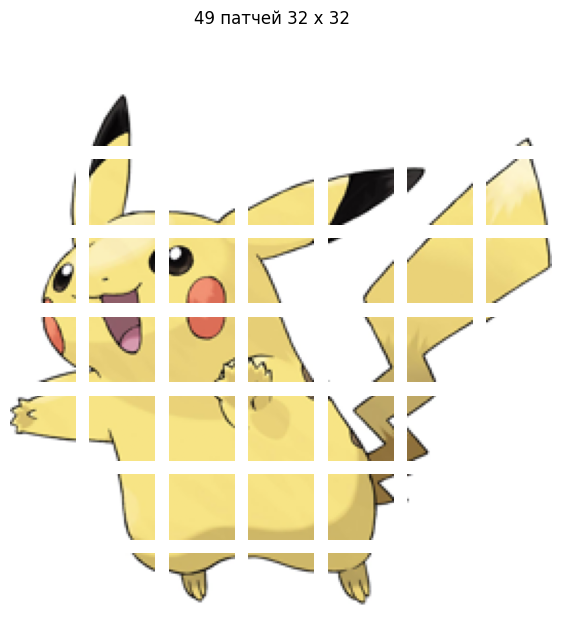

Патчей: 49
Размер патча в конфигурации CLIP: 32
Выход кодировщика изображений: (1, 50, 768)


In [8]:
pikachu_img = dataset[186]["image"].convert("RGB")
patches = image_to_patches(pikachu_img, patch_size=32, image_size=224)

fig, axes = plt.subplots(7, 7, figsize=(7, 7))
for patch, ax in zip(patches, axes.flatten()):
    ax.imshow(patch.reshape(32, 32, 3).numpy())
    ax.axis("off")
plt.suptitle("49 патчей 32 x 32")
plt.show()

pixel_values = clip_processor.image_processor(pikachu_img, return_tensors="pt")["pixel_values"].to(DEVICE)
with torch.no_grad():
    vision_out = clip_model.vision_model(pixel_values=pixel_values)
print("Патчей:", patches.shape[0])
print("Размер патча в конфигурации CLIP:", clip_model.config.vision_config.patch_size)
print("Выход кодировщика изображений:", tuple(vision_out.last_hidden_state.shape))

> ***Вопрос на подумать***
>
> Сравните сетку из 49 патчей с исходной картинкой. Почему ViT не делает токеном каждый пиксель? Во сколько раз меньше токенов у CLIP с патчем 32, чем у ViT с патчем 16, и чем приходится платить за такую экономию?
>
> ***Ответ: 1) В результате эксперемента выше изображение было разделено на 49 патчей размером 32×32 пикселя. Это подтверждается выводом патчей, размер патча 32 также совпадает с конфигурацией CLIP а выход кодировщика имеет размер (1, 50, 768). Это означает, что модель получила последовательность из 50 токенов — 49 патчей и одного дополнительного CLS-токена. 2) ViT не использует каждый пиксель как отдельный токен, потому что это привело бы к слишком длинной последовательности и большим затратам. (Из лекции) самовнимание имеет квадратичную сложность O(N^2) и каждый токен сравнивается с каждым. А кроме того отдельный пиксель сам по себе несёт мало информации, а патч позволяет учитывать сочетания пикселей, например текстуры и границы объектов. 3) При размере изображения 224×224 CLIP с патчем 32 получает 49 токенов-патчей, а ViT с патчем 16 — 196. Следовательно, токенов становится в 4 раза меньше. Такая экономия уменьшает вычислительные затраты, но приводит к потере пространственной детализации. То есть крупные патчи объединяют больше пикселей, поэтому модели сложнее замечать мелкие особенности изображения.***

# Задание 2. Zero-shot классификация

Задание 1 показало, что ViT превращает картинку в 49 токенов и [CLS]. Вектор [CLS] после линейной проекции – это эмбеддинг картинки размерности 512. Текстовый кодировщик CLIP выдаёт вектор той же размерности. После L2-нормализации оба вектора лежат на единичной гиперсфере, и косинусное сходство становится скалярным произведением.

Zero-shot классификация сравнивает картинку $x$ с текстовым описанием каждого класса $c$ и превращает косинусы в вероятности:

$$P(y = c \mid x) = \text{softmax}\left(\frac{\cos(I(x),\; T(\text{caption}_c))}{\tau}\right)$$

Здесь $I(x)$ – эмбеддинг картинки, $T(\text{caption}_c)$ – эмбеддинг описания класса, $\tau$ – температура. CLIP начинает обучение с $\tau = 0.07$ и выучивает $\tau \approx 0.01$.

**Реализуйте:**
- `get_clip_embeddings(images, texts)` – нормализованные эмбеддинги картинок и текстов.
- `calculate_probs(image_embs, text_embs, temperature)` – softmax от косинусов, делённых на температуру.

<details>
<summary><b>Подсказка</b></summary>

- подготовьте входы: `processor(text=texts, images=images, return_tensors="pt", padding=True, truncation=True).to(device)`
- вызовите `model(**inputs)` внутри `torch.no_grad()`
- возьмите `outputs.image_embeds` и `outputs.text_embeds` и поделите каждый на его норму `.norm(dim=-1, keepdim=True)`

</details>

In [9]:
def get_clip_embeddings(images, texts, model=clip_model, processor=clip_processor, device=DEVICE):
    """
    Нормализованные эмбеддинги CLIP для картинок и текстов.

    images : list[PIL.Image.Image]
        Картинки.
    texts : list[str]
        Тексты.

    Returns
    -------
    tuple[torch.Tensor, torch.Tensor]
        Эмбеддинги картинок (len(images), 512) и текстов (len(texts), 512) с L2-нормой 1.
    """
    # TODO: подготовьте входы процессором (text, images, padding=True, truncation=True), перенесите на device,
    # вызовите модель без градиентов и поделите image_embeds и text_embeds на их L2-нормы
    inputs = processor(text=texts, images=images, return_tensors="pt", padding=True, truncation=True).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        image_embs = outputs.image_embeds
        text_embs = outputs.text_embeds
        image_embs = image_embs / image_embs.norm(dim=-1, keepdim=True)
        text_embs = text_embs / text_embs.norm(dim=-1, keepdim=True)

    return image_embs, text_embs

In [10]:
try:
    test_imgs = [dataset[186]["image"].convert("RGB"), dataset[10]["image"].convert("RGB")]
    test_texts = [dataset[186]["text"], dataset[10]["text"], "a photo of a car"]
    i_e, t_e = get_clip_embeddings(test_imgs, test_texts)
    assert tuple(i_e.shape) == (2, 512), "Неверная размерность эмбеддингов картинок"
    assert tuple(t_e.shape) == (3, 512), "Неверная размерность эмбеддингов текстов"
    assert torch.allclose(i_e.norm(dim=-1).cpu(), torch.ones(2), atol=1e-4), "Эмбеддинги картинок не нормализованы"
    assert torch.allclose(t_e.norm(dim=-1).cpu(), torch.ones(3), atol=1e-4), "Эмбеддинги текстов не нормализованы"
    sims = (i_e @ t_e.T).cpu()
    assert sims[0, 0] > sims[0, 1] and sims[1, 1] > sims[1, 0], "Картинка должна быть ближе к своей подписи, чем к чужой"
    print_ok("get_clip_embeddings работает")
except Exception as e:
    print_error(f"Ошибка в get_clip_embeddings: {e}")

[OK] get_clip_embeddings работает


<details>
<summary><b>Подсказка</b></summary>

- косинусы всех пар – матричное произведение `image_embs @ text_embs.T`
- поделите их на `temperature`
- примените `.softmax(dim=-1)`, чтобы вероятности суммировались по классам

</details>

In [11]:
def calculate_probs(image_embs, text_embs, temperature):
    r"""
    Вероятности классов для zero-shot классификации.

    image_embs : torch.Tensor
        Нормализованные эмбеддинги картинок (n, d).
    text_embs : torch.Tensor
        Нормализованные эмбеддинги описаний классов (K, d).
    temperature : float
        Температура $\tau$.

    Returns
    -------
    torch.Tensor
        Матрица (n, K): softmax по классам от косинусов, делённых на temperature.
    """
    # TODO: посчитайте косинусы скалярным произведением, поделите на temperature и примените softmax по классам
    similarities = image_embs @ text_embs.T
    logits = similarities / temperature
    probs = torch.softmax(logits, dim=-1)
    return probs

In [12]:
try:
    torch.manual_seed(0)
    a = torch.nn.functional.normalize(torch.randn(4, 16), dim=-1)
    b = torch.nn.functional.normalize(torch.randn(5, 16), dim=-1)
    p = calculate_probs(a, b, temperature=0.5)
    assert tuple(p.shape) == (4, 5), "Ожидалась матрица (число картинок, число классов)"
    assert torch.allclose(p.sum(dim=-1), torch.ones(4), atol=1e-5), "Вероятности по классам должны суммироваться в 1"
    assert torch.allclose(p, torch.softmax(a @ b.T / 0.5, dim=-1), atol=1e-5), "Логиты – косинусы, делённые на temperature"
    assert calculate_probs(a, b, 0.01).max(dim=-1).values.mean() > calculate_probs(a, b, 1.0).max(dim=-1).values.mean(), \
        "При меньшей температуре распределение должно быть острее"
    print_ok("calculate_probs работает")
except Exception as e:
    print_error(f"Ошибка в calculate_probs: {e}")

[OK] calculate_probs работает


Классифицируем Pikachu по одиннадцати типам при трёх температурах: выученной в CLIP, начальной и $\tau = 1$. Косинусы на трёх графиках одни и те же, меняется только $\tau$: сравните, как распределяется вероятность по типам.

Температура, которую выучил CLIP: 0.0100


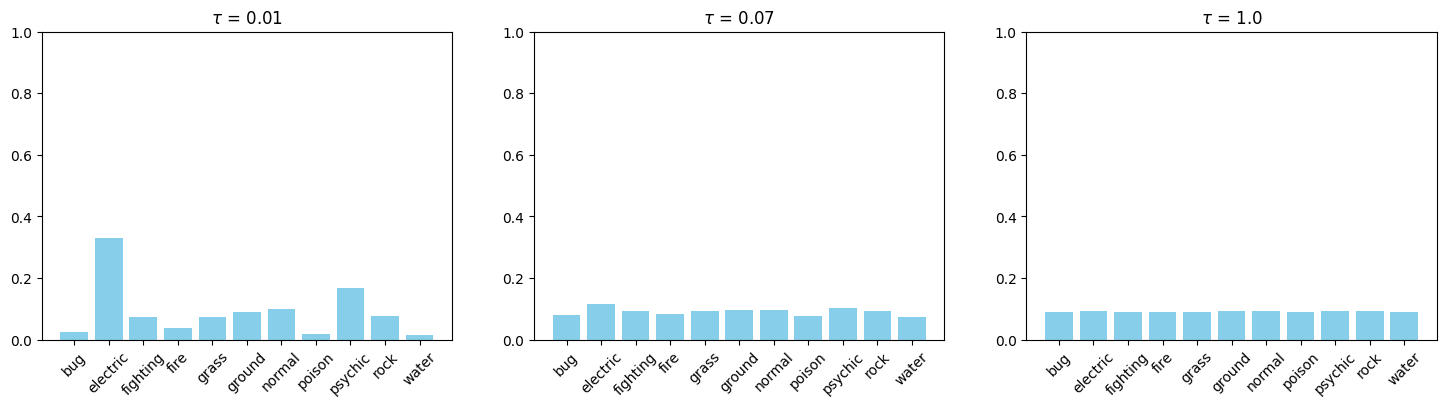

In [13]:
type_prompts = [f"a {t} type pokemon" for t in pokemon_types]
img_embs, txt_embs = get_clip_embeddings([pikachu_img], type_prompts)
print(f"Температура, которую выучил CLIP: {1 / clip_model.logit_scale.exp().item():.4f}")

temps = [0.01, 0.07, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, t in zip(axes, temps):
    probs = calculate_probs(img_embs, txt_embs, temperature=t)[0].cpu().numpy()
    ax.bar(pokemon_types, probs, color="skyblue")
    ax.set_title(f"$\\tau$ = {t}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
plt.show()

Одна картинка ничего не говорит о точности. Проверим, как часто CLIP угадывает тип на всех картинках с меткой и зависит ли это от формулировки промпта. Готовая ячейка ниже считает эмбеддинги картинок с меткой (`labeled_embs`) и номера верных типов в списке `pokemon_types` (`labeled_y`).

In [14]:
labeled_images = [dataset[i]["image"].convert("RGB") for i in labeled_idx]
labeled_embs = torch.cat([get_clip_embeddings(labeled_images[s:s + 32], [""])[0]
                          for s in range(0, len(labeled_images), 32)])
labeled_y = torch.tensor([pokemon_types.index(labels[i]) for i in labeled_idx])
print("Эмбеддинги картинок с меткой:", tuple(labeled_embs.shape))

Эмбеддинги картинок с меткой: (85, 512)


Сравним голое название типа `"{}"` и шаблон `"an illustration of a {}-type Pokémon"`. Для точности температура не нужна: softmax не меняет порядок классов, поэтому предсказание – тип с наибольшим косинусом. Ячейка печатает точность обоих вариантов и точность случайного угадывания.

In [15]:
dummy_img = dataset[0]["image"].convert("RGB")
for template in ["{}", "an illustration of a {}-type Pokémon"]:
    _, type_embs = get_clip_embeddings([dummy_img], [template.format(t) for t in pokemon_types])
    preds = (labeled_embs @ type_embs.T).argmax(dim=-1).cpu()
    accuracy = (preds == labeled_y).float().mean().item()
    print(f"{accuracy:.3f}  {template}")
print(f"Случайное угадывание: {1 / len(pokemon_types):.3f}")

0.212  {}
0.447  an illustration of a {}-type Pokémon
Случайное угадывание: 0.091


> ***Вопрос на подумать***
>
> Сравните три графика: почему одни и те же косинусы при $\tau = 1$ дают почти равномерное распределение, а при $\tau = 0.01$ – гораздо более резкое? По выводу ячейки выше сравните голое название типа и шаблон с доменом: почему формулировка промпта меняет точность?
>
> ***Ответ: 1) Температура $\tau$ влияет на распределение вероятностей после применения функции softmax. (Из лекции) CLIP использует косинусное сходство между эмбеддингами изображения и текста, а затем масштабирует полученные значения перед применением softmax. Это видно на результатах эксперимента выше. При температуре $\tau=0.01$ распределение получается наиболее резким. Для исходного изображения наибольшая вероятность приходится на класс `electric` (примерно 0,33), а следующая заметная вероятность — на `psychic` (примерно 0,17). При $\tau=0.07$ вероятности становятся более равномерными. При $\tau=1.0$ распределение практически равномерное. Вероятности всех 11 классов находятся около 0,1. Это происходит потому, что при маленькой температуре косинусные сходства делятся на маленькое число, из-за чего различия между оценками увеличиваются. Функция softmax сильнее выделяет класс с наибольшим сходством. При $\tau=1.0$ различия между оценками выражены слабее, поэтому вероятности становятся более равномерными. При этом порядок классов по сходству не меняется: `electric` остаётся наиболее вероятным классом на всех трёх графиках.2) Формулировка промпта также влияет на точность классификации. CLIP обучался сопоставлять изображения с текстовыми описаниями, поэтому контекст текста имеет значение. Это подтверждается вторым результатом эксперимента. При использовании только названий типов точность составила 0,212, а при использовании шаблона `an illustration of a {}-type Pokémon` она выросла до 0,447. А точность случайного угадывания составляет всего 0,091. Таким образом, шаблон с дополнительным контекстом показал результат более чем в 2 раза лучше, чем простые названия типов. Изменение формулировки промпта меняет текстовые эмбеддинги классов, а следовательно, и косинусное сходство между текстом и изображением. Поэтому точность классификации зависит от того, используется ли просто название типа или еще и корректное описание.***

# Задание 3. Поиск по изображениям

В задании 2 картинка сравнивалась с одиннадцатью описаниями классов. Тот же косинус работает и в обратную сторону: по тексту можно найти картинку среди сотен.

Индекс – это матрица эмбеддингов всех 500 картинок. Готовая функция `build_vector_index` собирает его: кодирует картинки батчами по 32 через `get_clip_embeddings` и склеивает эмбеддинги в матрицу $(500, 512)$ на CPU. Осталось написать сам поиск: запрос – нормализованный вектор, ответ – $k$ строк индекса с наибольшими косинусами.

**Реализуйте:**
- `retrieve_top_k(query_emb, idx_embs, k)` – косинусы и индексы $k$ ближайших векторов индекса.

In [16]:
def build_vector_index(ds, batch_size=32):
    """
    Векторный индекс картинок датасета.

    ds : datasets.Dataset
        Датасет с полем "image".
    batch_size : int
        Сколько картинок кодировать за раз.

    Returns
    -------
    torch.Tensor
        Нормализованные эмбеддинги картинок (len(ds), 512) на CPU.
    """
    all_embs = []
    for start in range(0, len(ds), batch_size):
        batch = ds[start:start + batch_size]
        images = [img.convert("RGB") for img in batch["image"]]
        img_embs, _ = get_clip_embeddings(images, [""])
        all_embs.append(img_embs.cpu())
    return torch.cat(all_embs)


index_embs = build_vector_index(dataset)
print("Размер индекса:", tuple(index_embs.shape))

Размер индекса: (500, 512)


<details>
<summary><b>Подсказка</b></summary>

- приведите запрос к форме $(1, d)$ (`reshape(1, -1)`) и перенесите оба тензора на CPU
- косинусы со всеми строками – `query @ idx_embs.T`
- $k$ наибольших значений и их номера даёт `torch.topk(sims[0], k=k)`

</details>

In [17]:
def retrieve_top_k(query_emb, idx_embs, k=3):
    """
    Поиск k ближайших векторов индекса.

    query_emb : torch.Tensor
        Нормализованный запрос (d,) или (1, d).
    idx_embs : torch.Tensor
        Индекс (n, d).
    k : int
        Сколько результатов вернуть.

    Returns
    -------
    tuple[torch.Tensor, torch.Tensor]
        Косинусы (k,) по убыванию и индексы строк (k,).
    """
    # TODO: посчитайте косинусы запроса со всеми строками индекса (оба тензора на CPU) и возьмите torch.topk
    query_emb = query_emb.cpu()
    idx_embs = idx_embs.cpu()
    query_emb = query_emb.reshape(1, -1)
    sims = query_emb @ idx_embs.T
    scores, indices = torch.topk(sims[0], k=k)
    return scores, indices

In [18]:
try:
    toy_index = torch.eye(5)
    toy_query = torch.nn.functional.normalize(torch.tensor([0.1, 0.0, 1.0, 0.5, 0.0]), dim=0)
    scores, indices = retrieve_top_k(toy_query, toy_index, k=3)
    assert len(indices) == 3, "retrieve_top_k должна возвращать k индексов"
    assert indices.tolist() == [2, 3, 0], f"Ожидались индексы [2, 3, 0], получено {indices.tolist()}"
    assert scores[0] >= scores[1] >= scores[2], "Косинусы должны идти по убыванию"
    _, indices_2d = retrieve_top_k(toy_query.reshape(1, -1), toy_index, k=1)
    assert indices_2d.tolist() == [2], "Запрос формы (1, d) должен работать так же"
    _, own = retrieve_top_k(index_embs[186], index_embs, k=1)
    assert own.tolist() == [186], "Картинка из индекса должна находить саму себя"
    print_ok("retrieve_top_k работает")
except Exception as e:
    print_error(f"Ошибка в retrieve_top_k: {e}")

[OK] retrieve_top_k работает


Найдём картинки по трём текстовым запросам и посмотрим на первые три результата каждого. В заголовке картинки – её косинус с запросом и начало подписи. Смотрите, какие признаки из запроса есть на найденных картинках: цвет, тип, форма.

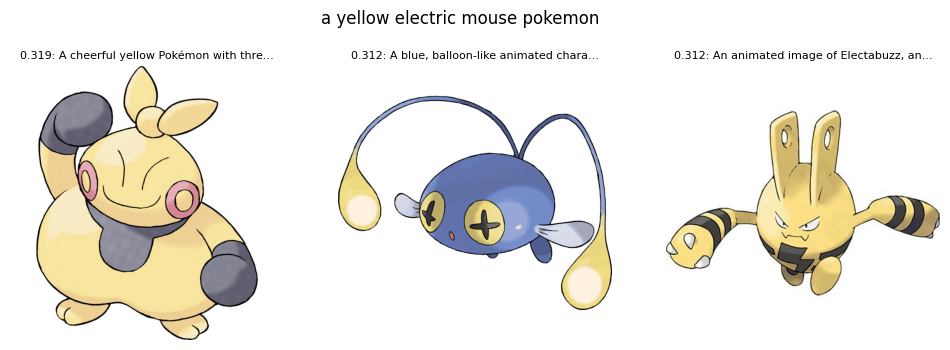

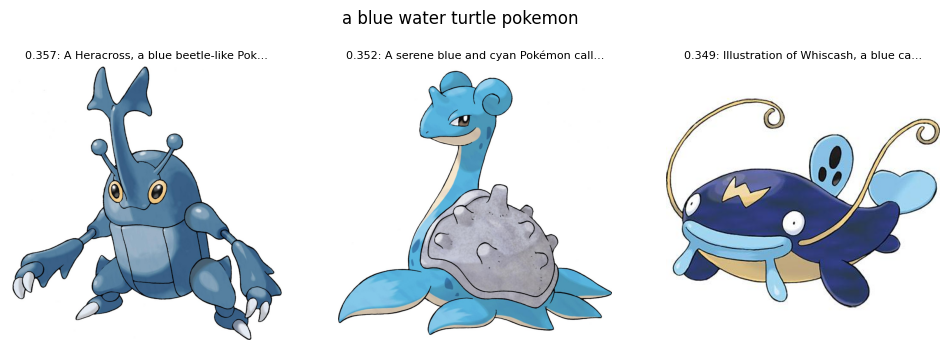

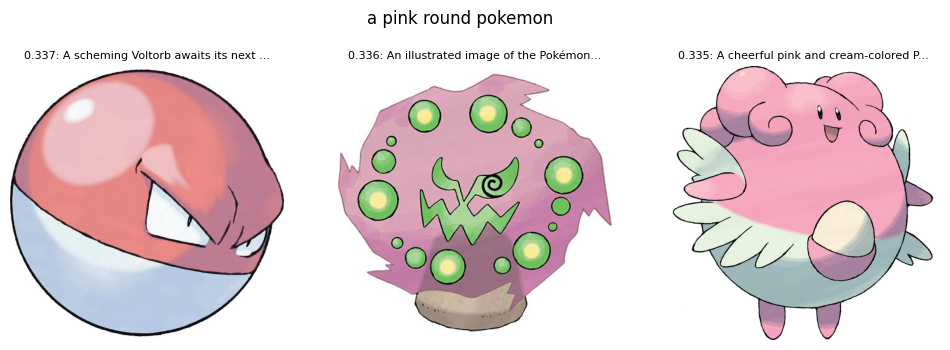

In [19]:
queries = ["a yellow electric mouse pokemon", "a blue water turtle pokemon", "a pink round pokemon"]
dummy_img = dataset[0]["image"].convert("RGB")
for query in queries:
    _, q_emb = get_clip_embeddings([dummy_img], [query])
    scores, top = retrieve_top_k(q_emb[0], index_embs, k=3)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, idx, score in zip(axes, top, scores):
        ax.imshow(dataset[int(idx)]["image"])
        ax.set_title(f"{score:.3f}: {dataset[int(idx)]['text'][:35]}...", fontsize=8)
        ax.axis("off")
    plt.suptitle(query)
    plt.show()

> ***Вопрос на подумать***
>
> Совпадают ли найденные картинки с запросами? Какие признаки CLIP учитывает уверенно, а какие нет?
>
> ***Ответ: Найденные изображения совпадают с текстовыми запросами лишь частично. Из эксперимента выше видно, что CLIP может находить изображения, похожие на запрос по отдельным признакам, но не всегда учитывает все характеристики одновременно. Например, для запроса `a yellow electric mouse pokemon` среди результатов есть жёлтые покемоны, однако не все они похожи на мышь. Также среди найденных изображений присутствует синий покемон, который не соответствует указанному цвету. Из результата эксперимента можно сделать вывод, что CLIP достаточно хорошо учитывает общие визуальные признаки, такие как цвет объектов, общую форму и силуэт, характерные особенности внешнего вида и общую смысловую близость изображения к текстовому описанию.Однако модель сложнее учитывает точный вид покемона, одновременное соответствие нескольким признакам (цвет, форма, тип), мелкие детали внешности и различия между похожими объектами.
(Из лекции) это проблема ограничения называется проблемой композициональности.***

# Задание 4. Вопросы к VLM и галлюцинации

CLIP только сравнивает картинки и тексты между собой: в задании 2 ответ выбирался из списка типов, в задании 3 – из картинок индекса. Чтобы получить ответ словами, нужна мультимодальная языковая модель. VLM – её частный случай для картинок: кодировщик превращает картинку в векторы, соединитель переводит их в пространство языковой модели, а языковая модель отвечает текстом:

$$X = \mathrm{Connector}\big(\mathrm{Encoder}(M)\big)$$

Здесь $M$ – картинка, $X$ – векторы, которые получает языковая модель.

В SmolVLM-256M кодировщик – SigLIP, языковая модель – SmolLM2. Такие модели обычно обучают в два этапа: сначала только соединитель на парах «картинка – подпись», затем языковую модель на диалогах – целиком или через LoRA, как на неделе 05. Картинка и вопрос собираются в чат-шаблон, модель достраивает ответ. Её главная слабость – галлюцинации: уверенный ответ о том, чего на картинке нет.

**Реализуйте:**
- `vqa(image, question, max_new_tokens)` – ответ VLM на вопрос по картинке, без текста шаблона.

<details>
<summary><b>Подсказка</b></summary>

- сообщение пользователя: `[{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]`
- строка запроса – `processor.apply_chat_template(messages, add_generation_prompt=True)`, входы – `processor(text=..., images=[image], return_tensors="pt").to(DEVICE)`
- генерация – `model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)` внутри `torch.no_grad()`
- декодируйте только новые токены: `out_ids[:, inputs["input_ids"].shape[1]:]` и `processor.batch_decode(..., skip_special_tokens=True)`

</details>

In [20]:
def vqa(image, question, max_new_tokens=40, model=vlm_model, processor=vlm_processor):
    """
    Ответ VLM на вопрос по картинке (жадное декодирование).

    image : PIL.Image.Image
        Картинка.
    question : str
        Вопрос.
    max_new_tokens : int
        Максимальная длина ответа в токенах.

    Returns
    -------
    str
        Сгенерированный ответ без чат-шаблона.
    """
    # TODO: соберите сообщение из картинки и вопроса, примените чат-шаблон, подготовьте входы процессором,
    # сгенерируйте ответ без сэмплирования и декодируйте только новые токены
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question}
            ]
        }
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image.convert("RGB")], return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = out_ids[:, inputs["input_ids"].shape[1]:]
    answer = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return answer.strip()

In [21]:
try:
    test_img = dataset[186]["image"].convert("RGB")
    ans = vqa(test_img, "What is in this image?", max_new_tokens=20)
    assert isinstance(ans, str) and len(ans) > 0, "vqa должна возвращать непустую строку"
    assert "Assistant:" not in ans, "В ответе не должно быть текста чат-шаблона"
    assert ans == vqa(test_img, "What is in this image?", max_new_tokens=20), "Жадное декодирование должно давать одинаковый ответ"
    print_ok("vqa работает")
except Exception as e:
    print_error(f"Ошибка в vqa: {e}")

[OK] vqa работает


Зададим вопросы о двух картинках. На Lickitung (картинка 10) шапки нет, на Patrat (картинка 14 из `holdout`) – есть: он её приподнимает. Сравним нейтральный вопрос с вопросом, который предполагает шапку. Смотрите, упоминает ли модель шапку в ответе на нейтральный вопрос и согласуется ли её ответ о цвете шапки с ответом на вопрос «да или нет».

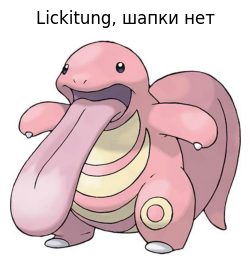

Q: What is in this image?
A: The image depicts a cartoon character, which appears to be a large, pink and yellow reptile-like creature with a long tail. The creature has a round, elongated body with a smooth, slightly curved

Q: What color is the hat?
A: The hat is pink.

Q: Is there a hat in this image? Answer yes or no.
A: No.



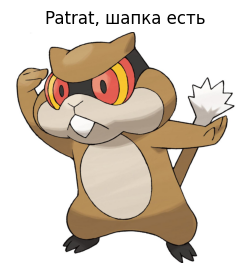

Q: What is in this image?
A: A Pokemon character resembling a cowboy.

Q: What color is the hat?
A: The hat is brown.

Q: Is there a hat in this image? Answer yes or no.
A: Yes.



In [22]:
hat_questions = ["What is in this image?", "What color is the hat?", "Is there a hat in this image? Answer yes or no."]
for name, img in [("Lickitung, шапки нет", dataset[10]["image"]), ("Patrat, шапка есть", holdout[14]["image"])]:
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.title(name)
    plt.axis("off")
    plt.show()
    for q in hat_questions:
        print(f"Q: {q}\nA: {vqa(img.convert('RGB'), q)}\n")

> ***Вопрос на подумать***
>
> Сравните ответы VLM о Lickitung на нейтральный вопрос и на вопрос о цвете шапки. Почему вопрос, который предполагает деталь, может вызвать галлюцинацию? Почему CLIP так ошибиться не может, а VLM может?
>
> ***Ответ: VLM — это генеративная модель, которая достраивает наиболее вероятное продолжение текста, поэтому она выдумывает деталь, чтобы дать связный ответ. CLIP — это модель сравнения, она не генерирует текст, а лишь измеряет сходство между изображением и описанием, поэтому не может придумать несуществующий объект это видно из результата эксперемента выше.***

## Требования к сдаче

| Задание | Что должно быть в блокноте | Баллы |
|---|---|---|
| 1. Изображение как последовательность патчей | `image_to_patches`, тест `[OK]`, ответ на вопрос | 1.25 |
| 2. Zero-shot классификация | `get_clip_embeddings`, `calculate_probs`, тесты `[OK]`, ответ на вопрос | 1.25 |
| 3. Поиск по изображениям | `retrieve_top_k`, тест `[OK]`, ответ на вопрос | 1.25 |
| 4. Вопросы к VLM и галлюцинации | `vqa`, тест `[OK]`, ответ на вопрос | 1.25 |
| **Итого** | | **5** |

Блокнот выполняется целиком без ошибок, все тесты печатают `[OK]`, на все «Вопросы на подумать» есть ответы, декларация заполнена.

## Декларация использования ИИ

**Инструмент: ChatGPT**

**Что изучали или уточняли с помощью ИИ** (концепции, API библиотек – без генерации кода):
- Принцип работы VIT. А именно разбиение изображения на патчи, формирование токенов и роль CLS-токена.
- Принцип работы CLIP - как происходит сопоставление эмбеддингов изображений и текстов с помощью косинусного сходства.
- Понятие галлюцинаций VLM и отличие их работы от CLIP.

**Какие ошибки обсуждали с ассистентом** (если были – сама проблема и как её нашли и исправили):
- В 4-ом задании была ошибка при реализации и проверке функции vqa возникли трудности с формированием запроса к VLM и обработкой результата генерации.
- Уточнялся порядок переключения среды Google Colab на GPU и проверки доступности CUDA (очень долго работала программа на последнем эксперементе)

**Что сделано полностью самостоятельно:**
- Первое задание
- Второе задание функцию (get_clip_embeddings)
- Третье задание функцию (retrieve_top_k)
- Ответы на вопросы из результатов эксперимента и лекций

## Полезные материалы и ссылки

- Dosovitskiy et al. [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929) – статья о ViT.
- Radford et al. [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020) – статья о CLIP.
- Hugging Face `transformers`: [документация CLIP](https://huggingface.co/docs/transformers/model_doc/clip).
- Hugging Face. [SmolVLM – small yet mighty Vision Language Model](https://huggingface.co/blog/smolvlm) и [карточка SmolVLM-256M-Instruct](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct).
- Датасет [diffusers/pokemon-gpt4-captions](https://huggingface.co/datasets/diffusers/pokemon-gpt4-captions).